# 06 · Simulación de producción por lotes

PSet 4, sección 5 y 9. Pasa los **35 lotes mensuales posteriores al corte** (cierres 2023-12 a 2026-10; los 34 primeros con objetivo y 2026-10, el mes en vivo, sin él) por el sistema, uno tras otro, con el mismo código que corre Kestra (`monitoreo/simulacion.py`, `monitoreo/produccion.py`):

1. al llegar el lote *t* se etiqueta el lote *t−1* (horizonte de un mes: nunca se usa una etiqueta antes de tiempo);
2. si la regla se dispara (rendimiento A7 o calendario de 12 lotes) se entrena un challenger y se aplica la regla de promoción; aquí la aprobación humana se **simula** siguiendo la regla (en Kestra es una tarea `Pause`);
3. el champion predice el lote *t* (preparado sin objetivo ni meses posteriores: `preparar_inferencia`) y arma la decisión (top 10, pesos 1/vol, tope de volatilidad);
4. se mide la deriva y se evalúan las alertas.

**Deriva inducida.** Los lotes 2025-05, 2025-06 y 2025-07 se reemplazan por un escenario sintético de crisis (volatilidades ×2, retornos del mes −10 % log y objetivo −10 % log, como marzo de 2020). Las filas quedan marcadas `sintetico=True`; no se escriben en la OBT.

Competidores de negocio en cada lote: B5 (todo el universo por igual), la **operación manual** (B7, `src/operacion_manual.py`, también devuelta en paralelo por la API) y el efectivo.

Se debe notar que el resultado de negocio de esta simulación **no** es el del PSet 3 (Sharpe 0,87 en el hold-out): tres meses del hold-out se reemplazaron por una crisis.

In [1]:
from pathlib import Path
import os, sys
RAIZ = Path.cwd().resolve()
while not (RAIZ / 'monitoreo').exists():
    RAIZ = RAIZ.parent
for p in (RAIZ, RAIZ / 'modelos'):
    sys.path.insert(0, str(p))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import mlflow
from src.datos import cargar
from src.pipeline import TARGET
from src.negocio import REGLA, RiesgoDiario, backtest, portafolio_universo, resumen
from src import operacion_manual as om
from monitoreo.simulacion import simular, LOTES_DERIVA
SEMILLA = 42
DOCS = RAIZ / 'docs'; FIG = DOCS / 'figuras'; SIM = DOCS / 'simulacion'
FIG.mkdir(parents=True, exist_ok=True); SIM.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

## 1. Datos y modelo inicial

Snapshot `obt_p4.parquet` (PORTAFOLIO_P4, ver `docs/datos_p4.md`). El modelo inicial es la **versión 1** del registro (el champion del PSet 3), pedida por número y no por alias: después de correr `produccion_lotes` en Kestra el alias `@champion` apunta a otra versión. Sin servidor de MLflow se usa la copia de `tests/fixtures/` (el mismo modelo).

In [2]:
obt, meta = cargar(RAIZ / 'modelos/data/obt_p4.parquet')
import urllib.request
URI = os.environ.get('MLFLOW_TRACKING_URI', 'http://localhost:5001')
try:
    urllib.request.urlopen(f'{URI}/health', timeout=3)
    mlflow.set_tracking_uri(URI)
    champion = mlflow.sklearn.load_model('models:/portafolio-inversiones-modelo/1')
    origen = f'registro v1 ({URI})'
except Exception as e:
    champion = mlflow.sklearn.load_model(str(RAIZ / 'tests/fixtures/modelo_champion'))
    origen = f'tests/fixtures (MLflow no disponible: {type(e).__name__})'
print(f"snapshot {meta['sha256'][:8]}; {len(obt)} filas; modelo: {origen}")

snapshot e008d6f4; 87178 filas; modelo: tests/fixtures (MLflow no disponible: URLError)


## 2. Simulación: sistema completo y champion fijo (sin reentrenar)

In [3]:
sistema = simular(champion, obt)
fijo = simular(champion, obt, aprobar=lambda comp: False)
seis = simular(champion, obt, k_evaluacion=6, enfriamiento=6)   # sensibilidad: comparar en 6 lotes
re = sistema['reentrenamientos']
re[['anio_mes_llegada', 'disparador', 'version_champion', 'version_challenger', 'hasta_anio_mes',
    'mae_champion', 'mae_challenger', 'retorno_champion', 'retorno_challenger', 'motivo_regla', 'aprobado']].round(4)

,anio_mes_llegada,disparador,version_champion,version_challenger,hasta_anio_mes,mae_champion,mae_challenger,retorno_champion,retorno_challenger,motivo_regla,aprobado
0,202412,calendario (12 lotes),1,r1,202410,0.1020,0.0866,-0.0567,-0.0360,cumple la regla,True
1,202503,rendimiento (A7),r1,r2,202501,0.0682,0.0703,0.0002,0.0164,su MAE es peor que el del champion,False
2,202508,rendimiento (A7),r1,r3,202506,0.1173,0.1065,-0.0886,-0.0896,no gana suficiente dinero,False
3,202511,rendimiento (A7),r1,r4,202509,0.0512,0.0509,0.0377,0.0292,no gana suficiente dinero,False
4,202604,rendimiento (A7),r1,r5,202602,0.0662,0.0655,0.0408,0.0728,cumple la regla,True


Lectura: la regla se dispara 5 veces (una por calendario al llegar 2024-12 y cuatro por rendimiento, A7: dos lotes etiquetados seguidos con MAE > 0,0801) y promueve 2 challengers: r1 (2024-12) y r5 (2026-04). **Ciclo sobre la deriva:** la A7 del lote 2025-07 (crisis inducida) dispara el reentrenamiento al llegar 2025-08; el challenger r3 se compara con el champion en el lote 2025-07, que ninguno vio, y no gana lo suficiente: se rechaza. Ningún modelo predice una caída que golpea a todas las acciones por igual, porque el modelo ordena acciones dentro del mes; lo que protege al cliente es el criterio de retirada (A8 → respaldo).

La comparación sigue al PDF (7.2.6): el lote etiquetado más reciente, con un margen de una desviación de la CV de la métrica de negocio (0,0134). La sección 3 compara el resultado con una variante que evalúa en 6 lotes.

## 3. Resultado de negocio lote a lote

In [4]:
dia, _ = cargar(RAIZ / 'modelos/data/obt_dia.parquet', grano='dia')
riesgo = RiesgoDiario(dia)
regla = {k: v for k, v in REGLA.items()}

def serie(pred):
    return backtest(pred, 'pred', riesgo=riesgo, **regla)

def etiquetadas(r):
    p = r['predicciones']
    return p[p['ret_pct_mes_siguiente'].notna()]          # el lote 2026-10 aun no tiene objetivo

s_sis, s_fijo, s_seis = (serie(etiquetadas(r)) for r in (sistema, fijo, seis))
base = etiquetadas(sistema).drop(columns=['pred', 'peso', 'decision', 'modelo_version'])
s_b5 = portafolio_universo(base)
s_om = om.portafolio(base, riesgo=riesgo)              # competidor B7, mismos lotes y misma regla de riesgo
tasa = base.groupby('anio_mes')['rf_mes_siguiente'].first()
s_ef = pd.DataFrame({'neto': tasa, 'rf': tasa, 'turnover': 0.0, 'bruto': tasa})
lotes = pd.DataFrame({'sistema': s_sis['neto'], 'champion_fijo': s_fijo['neto'], 'sistema_6_lotes': s_seis['neto'],
                      'b5_universo': s_b5['neto'], 'operacion_manual': s_om['neto'],
                      'no_hacer_nada_efectivo': s_ef['neto'], 'invertido_sistema': s_sis['invertido']})
version = sistema['predicciones'].groupby('anio_mes')['modelo_version'].first()
lotes['modelo_version'] = version
lotes['sintetico'] = lotes.index.isin(LOTES_DERIVA)
lotes['reentrenamiento'] = lotes.index.map(lambda m: '; '.join(
    f"{r.version_challenger} {'aprobado' if r.aprobado else 'rechazado'}" for r in re.itertuples()
    if r.anio_mes_llegada == m))
lotes.to_csv(SIM / 'resultado_lotes.csv')
resumen_negocio = pd.DataFrame({n: resumen(s) for n, s in
                                [('sistema', s_sis), ('champion_fijo', s_fijo), ('sistema_evaluacion_6_lotes', s_seis),
                                 ('b5_universo', s_b5), ('operacion_manual', s_om), ('no_hacer_nada_efectivo', s_ef)]}).T
resumen_negocio.loc['no_hacer_nada_efectivo', ['sharpe_neto', 'sharpe_bruto']] = np.nan
resumen_negocio.to_csv(SIM / 'resumen_negocio.csv')
resumen_negocio.round(3)

,sharpe_neto,sharpe_bruto,drawdown_max,turnover_prom,retorno_anual_neto
sistema,-0.229,-0.061,-0.369,1.770,-0.019
champion_fijo,0.051,0.234,-0.335,1.760,0.037
sistema_evaluacion_6_lotes,0.122,0.291,-0.373,1.760,0.049
b5_universo,-0.131,-0.121,-0.266,0.086,0.012
operacion_manual,0.346,0.439,-0.305,0.895,0.091
no_hacer_nada_efectivo,NaN,NaN,0.000,0.000,0.043


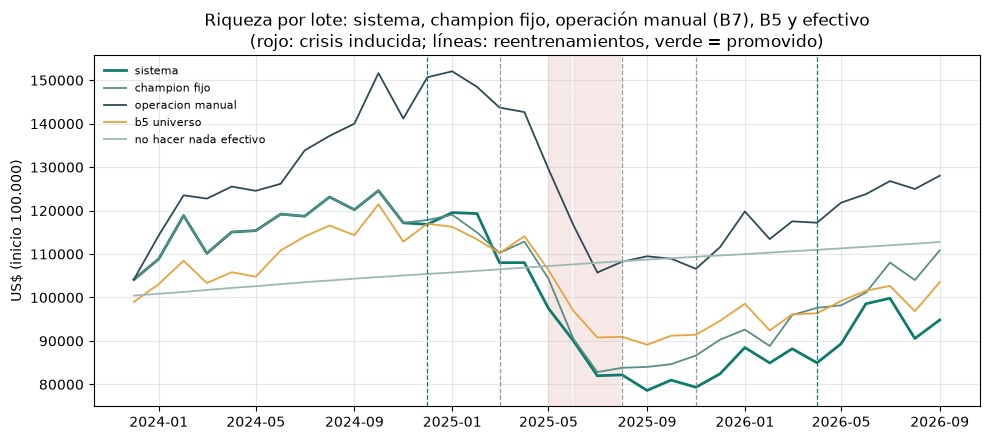

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for c, color in [('sistema', '#0F7B6C'), ('champion_fijo', '#5B8C85'), ('operacion_manual', '#2E4A55'), ('b5_universo', '#E8A33D'), ('no_hacer_nada_efectivo', '#9DB8B3')]:
    ax.plot(pd.PeriodIndex(lotes.index.astype(str), freq='M').to_timestamp(), 100_000 * (1 + lotes[c]).cumprod(), label=c.replace('_', ' '), color=color, lw=2 if c == 'sistema' else 1.3)
for m in LOTES_DERIVA:
    t = pd.Period(str(m), freq='M').to_timestamp()
    ax.axvspan(t, t + pd.offsets.MonthEnd(1), color='#B5473A', alpha=0.12, lw=0)
for r in re.itertuples():
    t = pd.Period(str(r.anio_mes_llegada), freq='M').to_timestamp()
    ax.axvline(t, color='#0F7B6C' if r.aprobado else '#999999', ls='--', lw=0.9)
ax.set_ylabel('US$ (inicio 100.000)'); ax.set_title('Riqueza por lote: sistema, champion fijo, operación manual (B7), B5 y efectivo\n(rojo: crisis inducida; líneas: reentrenamientos, verde = promovido)')
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / 'negocio_por_lote.png', dpi=150)

**¿Valió la pena actuar según la predicción?** Ver la tabla: se compara el sistema contra la línea base de negocio (B5, todo el universo por igual), contra no hacer nada (efectivo) y contra el modelo sin reentrenar. La conclusión se escribe en el documento técnico (sección 9) con estas cifras.

## 4. Desempeño por subgrupo (ética)

El universo no trae sector (la fuente no lo publica), así que los subgrupos son los que afectan a quién se le asigna capital: **tamaño** (quintil de dólares negociados del mes) y **volatilidad** (quintil de `vol_63d` del mes). Se excluyen los lotes sintéticos.

In [6]:
p = etiquetadas(sistema)
p = p[~p['sintetico']].copy()
p['tamano'] = p.groupby('anio_mes')['dolares_negociados_prom_21d'].transform(lambda x: pd.qcut(x, 5, labels=['Q1 pequeñas', 'Q2', 'Q3', 'Q4', 'Q5 grandes']))
p['volatilidad'] = p.groupby('anio_mes')['vol_63d'].transform(lambda x: pd.qcut(x, 5, labels=['Q1 baja', 'Q2', 'Q3', 'Q4', 'Q5 alta']))
def por(g):
    return pd.Series({'filas': len(g), 'mae': np.mean(np.abs(g[TARGET] - g['pred'])),
                      'acierto_direccional': np.mean(np.sign(g[TARGET]) == np.sign(g['pred'])),
                      'tasa_inclusion_%': 100 * (g['peso'] > 0).mean(),
                      'retorno_medio_incluidas': g.loc[g['peso'] > 0, 'ret_pct_mes_siguiente'].mean()})
subgrupos = pd.concat({'tamaño': p.groupby('tamano', observed=True).apply(por),
                       'volatilidad': p.groupby('volatilidad', observed=True).apply(por)})
subgrupos.to_csv(SIM / 'subgrupos.csv')
subgrupos.round(4)

filas     mae  acierto_direccional  tasa_inclusion_%  retorno_medio_incluidas
tamaño      Q1 pequeñas  2070.0  0.0686               0.4449            2.6087                  -0.0338
            Q2           2052.0  0.0695               0.4469            3.0702                   0.0111
            Q3           2053.0  0.0690               0.4657            2.8251                   0.0239
            Q4           2052.0  0.0682               0.4591            3.1676                   0.0146
            Q5 grandes   2066.0  0.0692               0.4714            3.3882                   0.0381
volatilidad Q1 baja      2070.0  0.0537               0.4213            3.1884                   0.0157
            Q2           2052.0  0.0593               0.4537            1.9981                  -0.0091
            Q3           2053.0  0.0656               0.4652            2.9226                   0.0250
            Q4           2052.0  0.0746               0.4703            6.9688                   0.0120
            Q5 alta      2066.0  0.0912               0.4777            0.0000                      NaN

## 5. Costo de cada tipo de error

Con US$ 100.000 y 10 acciones, cada inclusión es ~US$ 10.000 (más en las de menor volatilidad).

- **Falso positivo** (se incluye una acción que el mes siguiente cae): el costo es la pérdida de esa posición.
- **Falso negativo** (se deja fuera una acción del top 10 real del mes): el costo es la ganancia que no se tuvo frente a la que sí se incluyó.

In [7]:
filas = []
for mes, g in p.groupby('anio_mes'):
    inc = g[g['peso'] > 0]
    fp = inc[inc['ret_pct_mes_siguiente'] < 0]
    top_real = g.nlargest(10, 'ret_pct_mes_siguiente')
    fn = top_real[top_real['peso'] == 0]
    filas.append({'anio_mes': mes, 'falsos_positivos': len(fp),
                  'costo_fp_usd': float(-(fp['peso'] * fp['ret_pct_mes_siguiente']).sum() * 100_000),
                  'falsos_negativos_top10': len(fn),
                  'costo_fn_usd': float(((fn['ret_pct_mes_siguiente'].mean() - inc['ret_pct_mes_siguiente'].mean()) * 10_000 * len(fn)) if len(fn) else 0.0)})
errores = pd.DataFrame(filas).set_index('anio_mes')
errores.to_csv(SIM / 'costo_errores.csv')
errores.describe().loc[['mean', '50%', 'max']].round(1)

,falsos_positivos,costo_fp_usd,falsos_negativos_top10,costo_fn_usd
mean,4.2,2845.8,9.6,19375.1
50%,3.0,1637.6,10.0,17846.4
max,10.0,10166.9,10.0,44891.7


## 6. Tablas para docs/ (versión simulada fuera de Kestra)

In [8]:
for nombre in ('monitoreo', 'alertas', 'reentrenamientos'):
    sistema[nombre].to_csv(SIM / f'{nombre}_simulacion.csv', index=False)
seis['reentrenamientos'].to_csv(SIM / 'reentrenamientos_sensibilidad_6_lotes.csv', index=False)
cols = ['anio_mes', 'accion_key', 'ticker', 'pred', 'decision', 'peso', 'modelo_version', 'sintetico', TARGET]
sistema['predicciones'][cols].to_csv(SIM / 'predicciones_simulacion.csv', index=False)
print(sorted(x.name for x in SIM.iterdir()))

['alertas_simulacion.csv', 'competidores.csv', 'competidores_por_lote.csv', 'costo_errores.csv', 'monitoreo_simulacion.csv', 'predicciones_simulacion.csv', 'reentrenamientos_sensibilidad_6_lotes.csv', 'reentrenamientos_simulacion.csv', 'resultado_lotes.csv', 'resumen_negocio.csv', 'subgrupos.csv']
